# Portfolio VaR and PCA Analysis

## Background

I have always been interested in seeing how we can predict and quantify how risky are investments may be. Using methods learned, we can actually see!


All the calculations live in `risk_tool.py`. This notebook only calls them and shows the results. `import risk_tool as rt` loads the file, so each function is called as `rt.function_name(...)`. 

We select `SPY`, `EFA`, `IEF`, and `GLD`, as our tickers for our demo, as it has a large spread of variability. The chosen weights are scaled naively, but simulates a riskier portfolio.

We would think that this is a diversified portfolio, but in reality...... is it?

In [34]:
import pandas as pd
import risk_tool as rt
import matplotlib.pyplot as plt

In [4]:
tickers = ["SPY", "EFA", "IEF", "GLD"]
weights = [0.50, 0.25, 0.15, 0.10]
w = pd.Series(weights, index=tickers)

#### The weight vector
The four weights form a vector

$$
\mathbf{w} =
\begin{bmatrix} w_{\text{SPY}} \\ w_{\text{EFA}} \\ w_{\text{IEF}} \\ w_{\text{GLD}} \end{bmatrix}
=
\begin{bmatrix} 0.50 \\ 0.25 \\ 0.15 \\ 0.10 \end{bmatrix},
\qquad \sum_i w_i = 1, \quad w_i \ge 0
$$

Equities (SPY + EFA) are 75% of capital, bonds (IEF) 15% and gold (GLD) 10%.

Storing the weights as a pandas Series with the tickers as its index means every calculation after must match weights to assets **by name**, not by position. This matters because yfinance returns columns in alphabetical order (EFA, GLD, IEF, SPY), not the order typed here.

We use `rt.check_inputs(tickers, weights)` to check that there is one weight per ticker, that the weights add up to 1, and that none are negative.

In [5]:
rt.check_inputs(tickers, weights)

`check_inputs` stops with an error if, (1) the number of weights differs from the number of tickers, (2) the weights don't sum to 1 (within $10^{-6}$, to allow for rounding), or (3) any weight is negative.

In [6]:
prices = rt.load_prices(tickers) # downloads the prices from yfinance
prices

[*********************100%***********************]  4 of 4 completed


Ticker,EFA,GLD,IEF,SPY
Date,,,,
2012-01-03,32.864265,155.919998,76.110878,98.811646
2012-01-04,32.670494,156.710007,75.871490,98.966621
2012-01-05,32.186050,157.779999,75.885918,99.230125
2012-01-06,31.746824,157.199997,76.183464,98.974373
2012-01-09,31.869547,156.500000,76.197945,99.214661
...,...,...,...,...
2026-10-29,104.349998,368.570007,91.250000,769.359985
2026-10-30,103.370003,355.779999,91.760002,755.719971
2026-11-02,103.699997,361.649994,91.500000,752.099976


`yf.download(...)["Close"]` returns one row per trading day and one column per ticker: 3,704 trading days from January 2012 to October 2026.

These are **adjusted** closing prices: past prices are scaled down for dividends and splits, so the change from one day to the next reflects the total return an investor earned, not just the price move. Without the adjustment, every dividend payment would look like a small loss.

In order to backtest the VaR, we need a large amount of data: at least 1,250 trading days.

In [7]:
rt.check_history(prices)

OK: contians 3,732 days (need 1,250).


3732

#### Is there enough data?
The backtest will estimate the VaR each day from the previous 500 days, which allows the first 500 days train the model. At least 750 more days are needed for the Kupiec test to properly judge it. At a 5% breach rate, that's about 37 expected breaches, which means that the check requires 1250 days

$$
\text{usable days} \ge 500 + 750 = 1{,}250
$$

"Usable days" are the dates on which **every** ticker has a price (`len(prices.dropna())`), because a single late-starting ticker would shorten the whole dataset. All four ETFs trade back to 2012, so all 3,704 days are usable.

In [8]:
returns = rt.compute_returns(prices)
returns.tail()


Ticker,EFA,GLD,IEF,SPY
Date,,,,
2026-10-29,0.006462,-0.013226,0.004403,-0.003820
2026-10-30,-0.009391,-0.034702,0.005589,-0.017729
2026-11-02,0.003192,0.016499,-0.002834,-0.004790
2026-11-03,-0.005979,-0.006609,-0.003716,0.002992
2026-11-04,0.025611,0.036826,0.005485,0.016518


#### Daily returns
For each asset $i$ and day $t$, the simple daily return is

$$
r_{t,i} = \frac{P_{t,i} - P_{t-1,i}}{P_{t-1,i}} = \frac{P_{t,i}}{P_{t-1,i}} - 1
$$

which is what `.pct_change()` computes.

Note: The first day has no previous price, so its return is empty with `.dropna()` removing it, thus leaving 3,703 days.

Risk models use returns rather than prices because returns are comparable across assets where as prices are not really. For example, a \$5 move means something very different for a \$90 bond ETF than for a \$770 SPY share, while a 1% move means the same for both.

The result is a $T \times N$ matrix $R$, with $T = 3{,}703$ days and $N = 4$ assets, for our example. 

In [9]:
risk_share = rt.risk_shares(returns, w)
risk_share


,weight,risk_share
SPY,0.50,0.648393
EFA,0.25,0.316927
IEF,0.15,-0.002779
GLD,0.10,0.037459


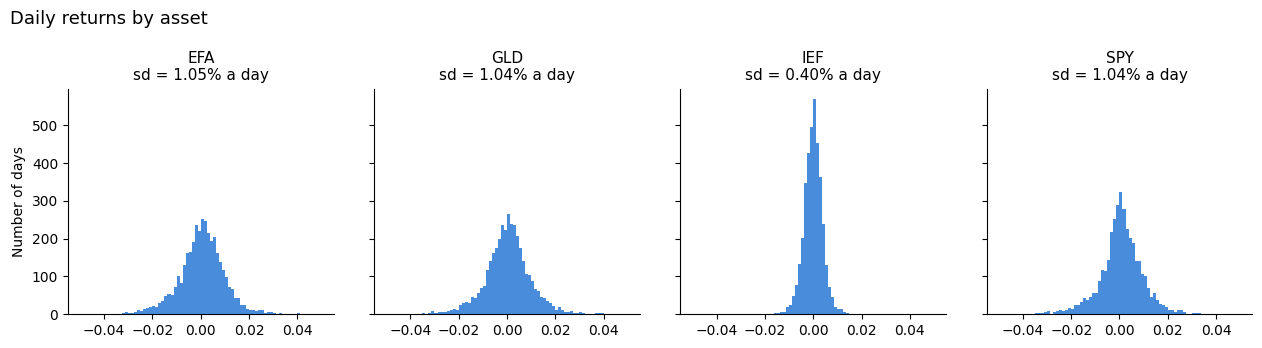

In [10]:
rt.plot_return_histograms(returns, 0.05, 80)

The returns for our selected ETFs are unimodel, but there are definitely skewed and have fat tails. 

#### Risk contributions

We begin the process of finding our risk contributors by preparing for PCA in three steps. The function `risk_shares()` applies the following:

*The process of finding the risk decomposition comes from Qian (2006)*


**1: The Covariance Matrix.** `returns.cov()` estimates the sample covariance of each pair of assets, given by

$$
\hat\sigma_{ij} = \frac{1}{T-1}\sum_{t=1}^{T}(r_{t,i}-\bar r_i)(r_{t,j}-\bar r_j),
$$

Where $t$ is the particular day, $T$ is the total days, $i$ and $j$ are the assets being compared, $r_{t,i}$ being asset $i$'s return on day $t$, $\bar r_i$ being asset $i$'s average daily return over all $T$ days.

Covariance gives us an understanding of, **if one stock returns above average, does the other one being compared also return above average?** The covariance is then calculated for each pair in the vectors, resulting in an arrangement of a $4 \times 4$ matrix $\Sigma$ (for this example). The diagonal holds each asset's variance, since $\operatorname{Cov}(X, X) = \operatorname{Var}(X)$. Meaning that the off-diagonal entries show how pairs of assets move together.


**2. Portfolio variance.** The portfolio's daily return is a weighted sum of the asset returns, $r_{p,t} = \mathbf{w}^\top \mathbf{r}_t$. By the variance of a linear combination,

$$
\sigma_p^2 = \operatorname{Var}(r_p)  = \sum_i \sum_j w_i\, w_j\, \sigma_{ij}
$$

which gives us $$\operatorname{Var}(r_p) = \mathbf{w}^\top \Sigma\, \mathbf{w}$$





**3. Split the variance by asset.** 
To calculate risk share, we have to differentiate portfolio variance with respect to the weights, giving us $$\partial \sigma_p^2 / \partial \mathbf{w} = 2\Sigma\mathbf{w}$$ this is the same derivative used to derive PCA, but we have divide it with respect with the weight instead of the eigenvectors. Since our weights are not eigenvectors, we do not equate to zero and solve. 

Each asset's share of portfolio variance follows Qian (2006, eq. 2), written in matrix form:

$$
\text{RS}_i = \frac{w_i\,(\Sigma\mathbf{w})_i}{\mathbf{w}^\top \Sigma\, \mathbf{w}}, \qquad \sum_i \text{RS}_i = 1
$$

where $(\Sigma\mathbf{w})_i = \operatorname{Cov}(r_i, r_p)$ measures how much asset $i$ moves with the whole portfolio. A negative covariance in this case would indicate being the asset acts as a hedge.

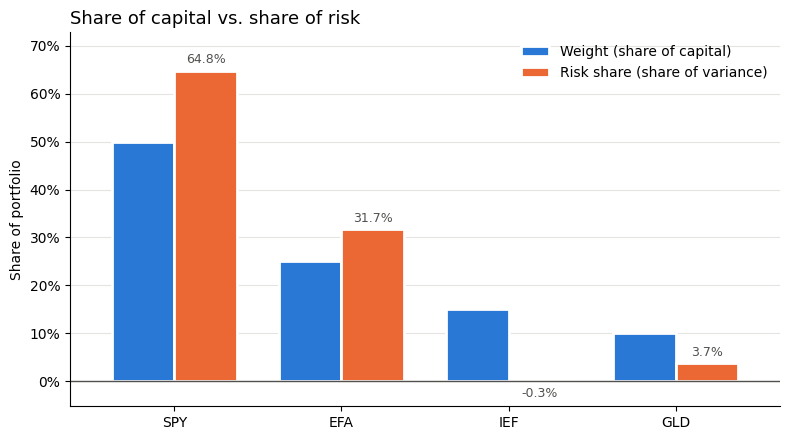

In [11]:
rt.plot_risk_shares(risk_share)

From our graph, we see that the blue bars show each asset's share of capital, whereas the orange bars show its share of risk. Where orange is taller than blue (e.g., SPY, EFA), it means that the asset contributes more risk than its weight suggests. Where it's shorter (e.g., IEF, GLD), it contributes less risk. Interestingly, IEF's orange bar sits at or below zero.

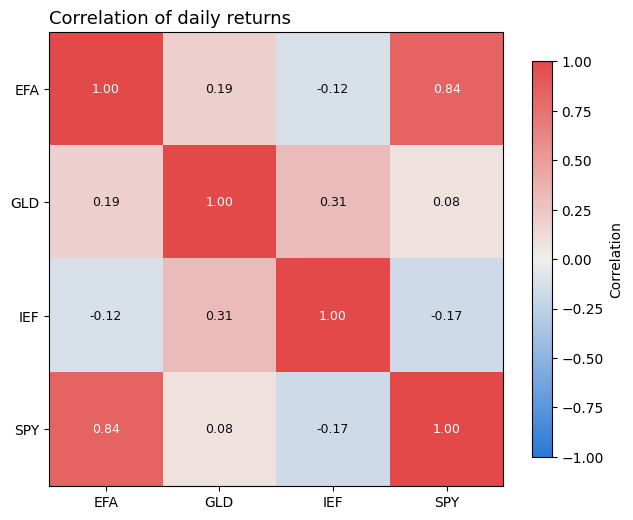

In [12]:
rt.plot_correlations(returns)

#### Correlation Matrix Graph

Each cell/block is the correlation between two assets' daily returns. In detail, the formula gives it as their covariance scaled by both volatilities, where 

$$
\operatorname{Corr}(i,j) = \rho_{ij} = \frac{\sigma_{ij}}{\sigma_i\,\sigma_j}, \qquad -1 \le \rho_{ij} \le 1
$$

The colour scale is fixed from −1 (blue, moves opposite) through 0 (gray, unrelated) to +1 (red, moves together). Note that the this correlation matrix is symmetric.

**Brief Analysis**

from the period for our selected data, which is ~3000 days since the latest run:

- **SPY and EFA: 0.84.** US and international stocks move together most of the time, so holding both adds little diversification. This is why their combined risk share (97%) is so much higher than their weight (75%).
- **IEF with stocks: −0.12 to −0.17.** Over the full period, bonds moved slightly against stocks, which is why IEF's risk share is slightly negative. This relationship has reversed since (around) 2021. Please see the rolling correlation graph below!. 
- **GLD and IEF: 0.31.** Gold and bonds share some behaviour, but not a lot. Both are assets investors buy in uncertain times. 
- **GLD with stocks: 0.08 to 0.19.** Gold is close to independent of equities, so its risk share (~3.7%) is well below its weight (10%).

#### Aside: Inflation

I wanted to make some diagrams that illustrates the correlation between SPY and bonds, since bonds are such a hot topic right now.

<Axes: title={'center': 'SPY–IEF 1-year rolling correlation'}, xlabel='Date'>

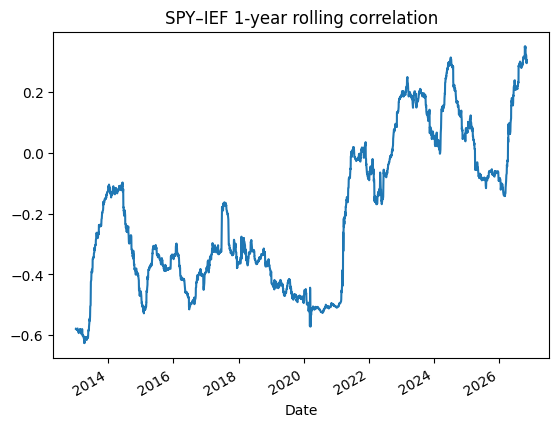

In [13]:
returns["SPY"].rolling(252).corr(returns["IEF"]).plot(title="SPY–IEF 1-year rolling correlation")

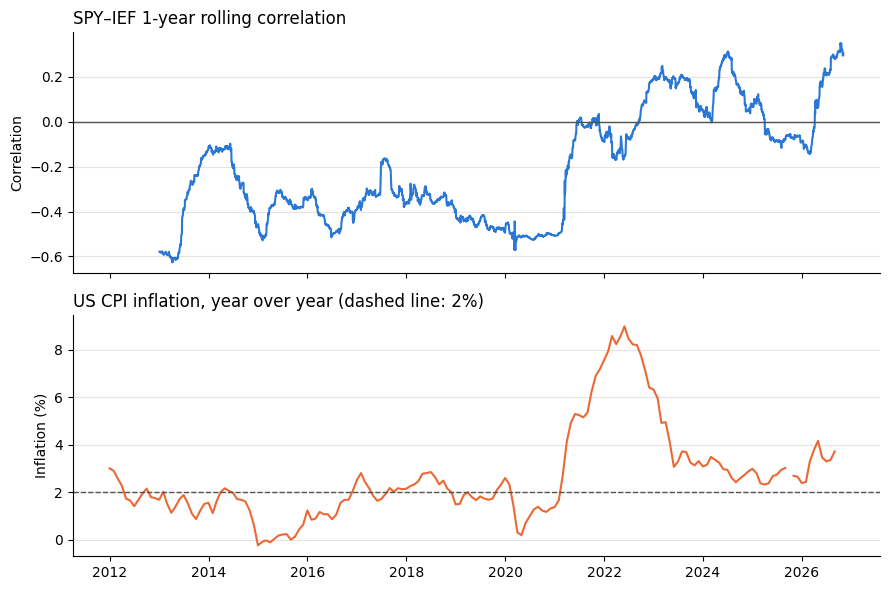

In [14]:
#US Consumer Price Index, monthly, from FRED
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL"
cpi = pd.read_csv(url, index_col=0, parse_dates=True).iloc[:, 0]
inflation = cpi.pct_change(12, fill_method=None) * 100    
inflation = inflation.loc["2012":]

roll_corr = returns["SPY"].rolling(252).corr(returns["IEF"])

#stacked panels sharing the same dates
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 6))

ax1.plot(roll_corr, color="#2a78d6")
ax1.axhline(0, color="#52514e", linewidth=1)
ax1.set_ylabel("Correlation")
ax1.set_title("SPY–IEF 1-year rolling correlation", loc="left")

ax2.plot(inflation, color="#eb6834")
ax2.axhline(2, color="#52514e", linewidth=1, linestyle="--")
ax2.set_ylabel("Inflation (%)")
ax2.set_title("US CPI inflation, year over year (dashed line: 2%)", loc="left")

for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

From what we can see during the massive increase in inflation during the pandemic era, had an effect on the bond and stock market. Essentially, the bond hedge diappears as intrest rates rose. We can observe that the correlation increased as the inflation increased. 

Aside - Finished

### Principal Component Analysis

We want to ask the question on how many independent sources of risk does the portfolio really have? PCA allows us to find the answer by calculating the combinations of assets that capture the most variation in returns. 

The solution to solving PCA is to find that the principal components are the eigenvectors $\mathbf{v}_k$ of $C$, and each eigenvalue $\lambda_k$ is the variance of that component:

Given that $C$ is our correlation matrix

$$
C\,\mathbf{v}_k = \lambda_k\,\mathbf{v}_k, \qquad \text{share explained}_k = \frac{\lambda_k}{\sum_j \lambda_j}
$$



In [15]:
explained, loadings = rt.pca_concentration(returns)
print(loadings.round(4))
print(explained.round(4))

           PC1     PC2     PC3     PC4
Ticker                                
EFA     0.6912  0.0609  0.1171  0.7105
GLD     0.1431  0.7131 -0.6806 -0.0881
IEF    -0.1713  0.6975  0.6958 -0.0078
SPY     0.6873 -0.0359  0.1974 -0.6981
PC1    0.4765
PC2    0.3278
PC3    0.1582
PC4    0.0376
dtype: float64


PCA is primarily used to reduce dimensions of the dataset and prevent overfitting. Here, PCA finds the directions along which the ETFs daily returns vary the most. Each direction is an eigenvector, whose entries show how much each ETF takes part in it. Each eigenvector comes with an **eigenvalue**, which is the variance of the *standardized* returns along that direction. Dividing an eigenvalue by the sum of all eigenvalues gives the **share of total variation** that component explains.

In our case, PCA is used to measure concentration rather than to reduce dimensions. The first component (PC1) explains 47.6% of all variability across our ETFs, and they are driven mainly by SPY and EFA. We can interpret this first component to be a Global Equity factor, as SPY and EFA covers US and international stocks (excluding Canada). 

We can take a closer look in our PC1 and reveal that SPY and EFA has a large loading of the component. This means the portfolio's biggest source of variation is also where most of its capital sits, 75% is in two global equity ETFs (predefined in our question) that move largely together. This suggests that the portfolio is concentrated, and we would be more diversified if we were to add more weight on to assets in different components. 

Our second component (PC2, orthogonal to PC1) explains nearly 32.8% of the variability, and they are loaded by the gold and bond ETF's as they are left over from PC1. This reveals that their size is due to how independent they are from stocks. We can interpret this component as the interest rate factor due to the component having large holdings in gold and treasuries and almost none in stocks (GLD 0.71, IEF 0.70, SPY −0.04, EFA 0.06). Note that even if they were uncorrelated, the variation would explain 25%, so we see a weak correlation between gold and bonds as 32.8% - 25% = 7.8%.

Upon closer inspection of PC2, we find that gold and bonds are exposed to interest rates. As rates fall, existing bonds become more valuable, hence bond prices increases. As for gold, since it does not pay interest, as rates fall, gold prices rise as there are less to give up on for holding them and vice versa. Due to the weights that we imposed at the beginning of this study, we find that it is difficult to balance PC1 and PC2 since stocks take a large portion of the portfolio. 

However, looking at PC3 and PC4, we would assume that they contradict what we just explained. However, those are just days/components when they disagree with each other, which is still informative, as we see that gold and bonds do tend to disagree with each other quite a bit. However, we see that US Stocks and other developed markets rarely diverge from each other, which actually supports our first PC1 finding

A naive assumption that there are 4 distinct risk factors would be incorrect, since uncorrelated equities would return all principle components to be 0.25, since 1/4.

We can make the conclusion that ~80% of is explained by two principle components. Meaning that it is not as diversified as initially assumed.

### VAR: Value at Risk

Value at risk asks the question of: "On a bad day, how much could I can lose?". Where the confidence level dictates the level of "bad". 
We use both historical and parametric (meaning the assumptions of returns being normal are true). 

Historical VaR uses the actual past returns, so it captures the real ups and downs of the market without assuming any particular shape. Parametric VaR assumes returns are normally distributed, so it only needs the mean and standard deviation, which makes it simple to compute, scale and update. The downside is that at higher confidence levels, parametric VaR becomes inaccurate, because real returns have fat tails: extreme days happen more often than a normal distribution expects.

In [16]:
port = rt.portfolio_returns(returns, w)
port.describe()

count    3731.000000
mean        0.000431
std         0.007691
min        -0.079227
25%        -0.003010
50%         0.000570
75%         0.004282
max         0.075026
dtype: float64

Taking a look at our portfolio, we see that over 3000+ days, the mean return is of 0.04% a day with a standard deviation of 0.77% (as of Nov.3)

In [17]:
historical = rt.var_historical(port, 0.95)
print(historical)

-0.011456797172351301


In [18]:
parametric = rt.var_parametric(port, 0.95)
print(parametric)

-0.01221889229632474


By taking the 5% quantile, we observe that the historical VaR sits at around -1.145%, which vary slightly with our parametric VaR of -1.122%. 

The interpretation:
The 95% historical VaR is −1.15%, on **95% of days the portfolio lost less than 1.15%, and on the worst 5% of days, it lost more.**

Note that the parametric calculation uses only the mean and standard deviation. Since it is a bell curve, we would use a z-score of 1.645. 

When we take a closer look and select a strict confidence level, things begin to change.

In [19]:
print(rt.var_historical(port, 0.99))
print(rt.var_parametric(port, 0.99))

-0.02054459494401669
-0.017460141177530794


At 99%, historical VaR is -2.055% but parametric VaR is only -1.745%. This shows that the normal model understates the loss by about ~0.31%. Since real returns have fat tails (meaning more extreme days than a normal distribution assumes), meaning that the normal model would capture less of the extremities that is displayed in the real market. 

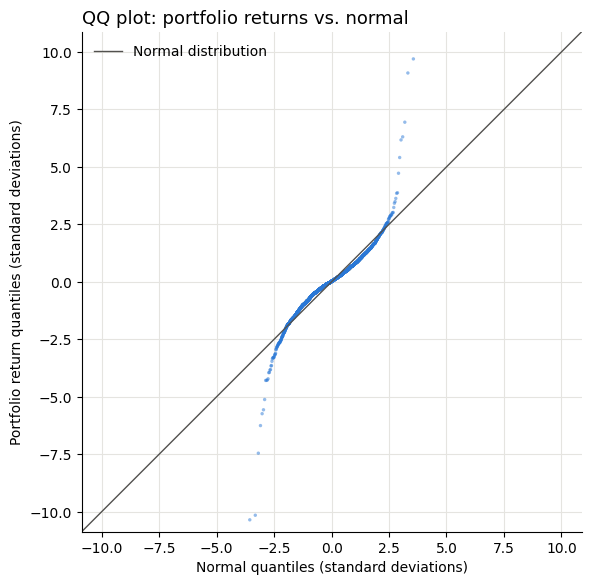

In [20]:
rt.qq_plot(port)

This QQ plot shows us that our distribution of returns are not normal, and the trailing tails on the QQ plot suggests why we see differences in the higher levels of confidence being drastically different.

We can also calculate the Expected Shortfall, or Conditional VaR (CVaR), to see on average how badly we lose in the worse 5% of time. 

In [21]:
cvar = rt.expected_shortfall(port)

print(cvar)

-0.017806061708343826


For our interpretation, we can say that on the worst 5% of days, the portfolio lost 1.78% on average. That is about 1.5 times the 95% VaR of −1.15%, for a really bad day, the loss usually goes well past the VaR line.

Note that expected shortfall can never be higher than the cutoff point of VaR. Since it is the average of the losses *beyond* the level.

### Begin Backtesting!

We begin backtesting by selecting calculating the historical VaR for a 500 day window. Meaning that the first 500 days would not have a calculation due to it being training data. We selected 500 as an arbitrarily large number so that the Kupic test can be ran and hypothesis tested. 

In [25]:
rolling_historical = rt.rolling_var(port, "historical", 0.95, 500)
print(rolling_historical) 

rolling_parametric = rt.rolling_var(port, "parametric", 0.95, 500)
print(rolling_parametric) 

Date
2012-01-04         NaN
2012-01-05         NaN
2012-01-06         NaN
2012-01-09         NaN
2012-01-10         NaN
                ...   
2026-10-29   -0.011014
2026-10-30   -0.011014
2026-11-02   -0.011014
2026-11-03   -0.011014
2026-11-04   -0.011014
Length: 3731, dtype: float64
Date
2012-01-04         NaN
2012-01-05         NaN
2012-01-06         NaN
2012-01-09         NaN
2012-01-10         NaN
                ...   
2026-10-29   -0.012548
2026-10-30   -0.012543
2026-11-02   -0.012549
2026-11-03   -0.012553
2026-11-04   -0.012556
Length: 3731, dtype: float64


Next, we check each day and find, was the actual return worse than that day's VaR? A day where it was is called a "breach".

In [28]:
exceed_hist = rt.exceeds(port, rolling_historical)
exceed_param = rt.exceeds(port, rolling_parametric)

print(f"Historical: {exceed_hist.sum()} breaches in {len(exceed_hist)} days ({exceed_hist.mean():.1%})")
print(f"Parametric: {exceed_param.sum()} breaches in {len(exceed_param)} days ({exceed_param.mean():.1%})")

Historical: 183 breaches in 3231 days (5.7%)
Parametric: 167 breaches in 3231 days (5.2%)


From this, we can say that at 95%, we expect breaches on 5% of days on a total of 3231 days (as of Nov.4). Historical VaR was breached 183 days (5.7%) and parametric VaR on 167 days (5.2%). Both are a little above 5%, so the VaR was beaten slightly more often than it promised. In other words, VaR slightly underestimated the risk of this portfolio. 

In [33]:
rt.exceedances_by_year(exceed_hist, 0.95)

,breaches,days,expected,rate
year,,,,
2013,0,1,0.1,0.000
2014,10,252,12.6,0.040
2015,20,252,12.6,0.079
2016,11,252,12.6,0.044
2017,1,251,12.6,0.004
2018,37,251,12.6,0.147
2019,8,252,12.6,0.032
2020,25,253,12.7,0.099
2021,6,252,12.6,0.024


From the following table, we can observe that in 2018, 2020, and 2022, there was a rate of ~10% of the year being breaches. Comparing it to our confidence level of 95%, 2018 in particular was 3x more breaches than expected. 

On average, our model seems to be accurate and VaR was about as accurate as calculated. 

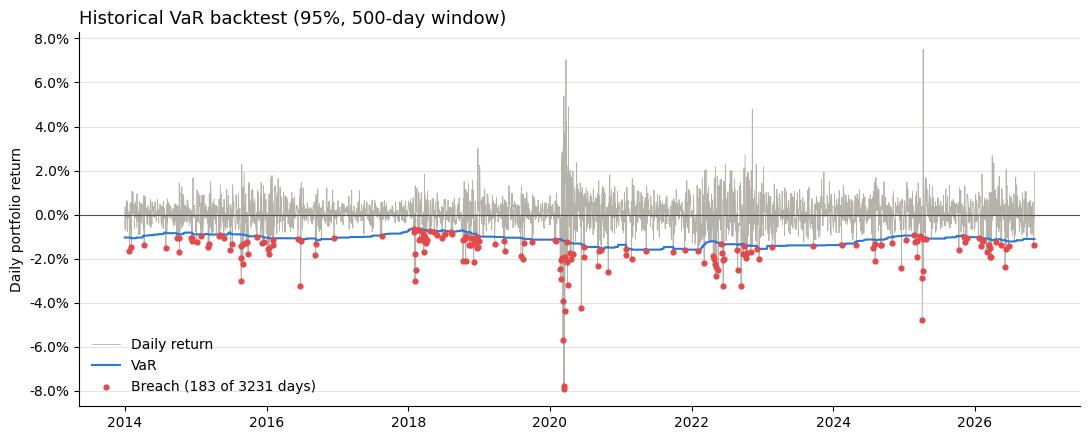

In [30]:
rt.plot_backtest(port, rolling_historical, exceed_hist,
                 title="Historical VaR backtest (95%, 500-day window)")

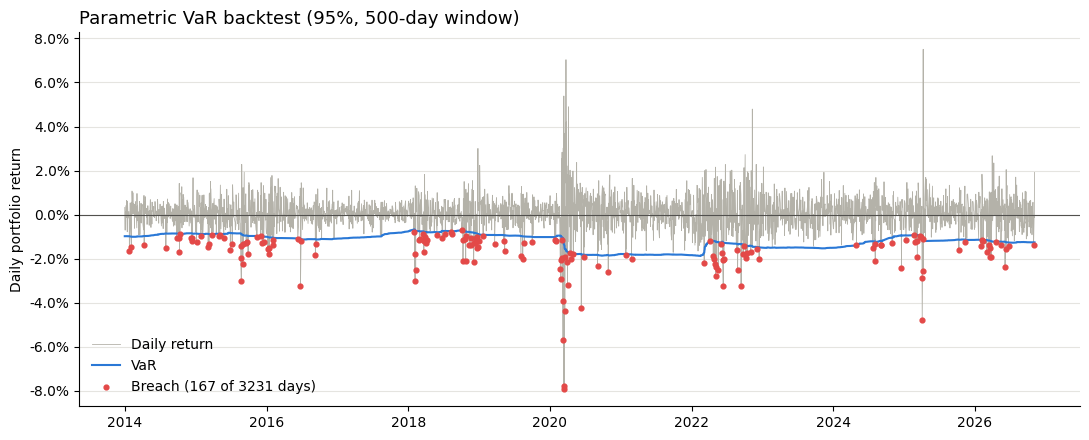

In [35]:
rt.plot_backtest(port, rolling_parametric, exceed_param,
                 title="Parametric VaR backtest (95%, 500-day window)")

In plotting our breaches, we observe that our breaches are almost clustered in a way; evidently in 2018, 2020, and 2022. These clusters of breaches in VaR are usually correlated with large economic news that were often unpredictable. For example, 2020 with the COVID pandemic freezing global economic trade, productivity and all aspects of life. Likewise, 2022 had the conflict between Ukraine and Russia, causing economic and energy turmoil in Europe.

The breaches reacts only in clusters during critical times, and the VaR is too slow to adjust back. The 500 day window is too slow and cannot catch up with the breaches that already happened. After a breach, the line stays flat and overstates the risks due to its previous shock. 